<a href="https://colab.research.google.com/github/annasehgal/final-project-tech-68/blob/main/Anna_TECH_68_Machine_learning_for_business_in_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wildlife Strike Aircraft Damage Prediction

**Goal:** Predict whether a wildlife strike results in aircraft damage using flight characteristics, wildlife attributes, and environmental conditions. Compare multiple classification models and identify the factors most influential in predicting damage risk.

**Importance:** Wildlife strikes can create safety risks and costly aircraft damage. Identifying the factors associated with a higher risk of damage could help better understand which strike conditions are most consequential.

**Dataset:** FAA Wildlife Strike Database (`Public.xlsx`), containing reported wildlife strike incidents and information about the aircraft, flight conditions, wildlife involved, and resulting damage. The data was obtained from the FAA Wildlife Strike Database: https://wildlife.faa.gov/.

## Setup

### Standard imports

In [3]:
# data manipulation/analysis and fast multi-dimensional numerical array processing.
import pandas as pd
import numpy as np
# Plotting libraries
import seaborn as sns
import matplotlib.pyplot as plt

## Load and Understand the Data

In [4]:
import io
import zipfile
import requests

url = "https://wildlife.faa.gov/assets/database_excel.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("Public.xlsx") as f:
        df = pd.read_excel(f)

In [5]:
df.head()

,INDEX_NR,INCIDENT_DATE,INCIDENT_MONTH,INCIDENT_YEAR,TIME,TIME_OF_DAY,AIRPORT_ID,AIRPORT,LATITUDE,LONGITUDE,...,NR_INJURIES,NR_FATALITIES,COMMENTS,IMAGE,REPORTED_NAME,REPORTED_TITLE,SOURCE,PERSON,LUPDATE,TRANSFER
0,608242,1996-06-22,6,1996,NaN,NaN,KSMF,SACRAMENTO INTL,38.69542,-121.59077,...,NaN,NaN,/Legacy Record 100001/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
1,608243,1996-06-26,6,1996,NaN,NaN,KDEN,DENVER INTL AIRPORT,39.85841,-104.667,...,NaN,NaN,/Legacy Record 100002/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
2,608244,1996-07-01,7,1996,NaN,NaN,KOMA,EPPLEY AIRFIELD,41.30252,-95.89417,...,NaN,NaN,/Legacy Record 100003/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
3,608245,1996-07-01,7,1996,NaN,NaN,KIAD,WASHINGTON DULLES INTL ARPT,38.94453,-77.45581,...,NaN,NaN,/Legacy Record 100004/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0
4,608246,1996-07-01,7,1996,NaN,NaN,KLGA,LA GUARDIA ARPT,40.77724,-73.87261,...,NaN,NaN,/Legacy Record 100005/,False,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,2007-12-20,0


In [6]:
print("Dataset shape:", df.shape)

Dataset shape: (361408, 102)


In [7]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows: 361,408
Columns: 102


In [8]:
df.columns.tolist()

['INDEX_NR',
 'INCIDENT_DATE',
 'INCIDENT_MONTH',
 'INCIDENT_YEAR',
 'TIME',
 'TIME_OF_DAY',
 'AIRPORT_ID',
 'AIRPORT',
 'LATITUDE',
 'LONGITUDE',
 'RUNWAY',
 'STATE',
 'FAAREGION',
 'LOCATION',
 'OPID',
 'OPERATOR',
 'REG',
 'FLT',
 'AIRCRAFT',
 'AMA',
 'AMO',
 'EMA',
 'EMO',
 'AC_CLASS',
 'AC_MASS',
 'TYPE_ENG',
 'NUM_ENGS',
 'ENG_1_POS',
 'ENG_2_POS',
 'ENG_3_POS',
 'ENG_4_POS',
 'PHASE_OF_FLIGHT',
 'HEIGHT',
 'SPEED',
 'DISTANCE',
 'SKY',
 'PRECIPITATION',
 'AOS',
 'COST_REPAIRS',
 'COST_OTHER',
 'COST_REPAIRS_INFL_ADJ',
 'COST_OTHER_INFL_ADJ',
 'INGESTED_OTHER',
 'INDICATED_DAMAGE',
 'DAMAGE_LEVEL',
 'STR_RAD',
 'DAM_RAD',
 'STR_WINDSHLD',
 'DAM_WINDSHLD',
 'STR_NOSE',
 'DAM_NOSE',
 'STR_ENG1',
 'DAM_ENG1',
 'ING_ENG1',
 'STR_ENG2',
 'DAM_ENG2',
 'ING_ENG2',
 'STR_ENG3',
 'DAM_ENG3',
 'ING_ENG3',
 'STR_ENG4',
 'DAM_ENG4',
 'ING_ENG4',
 'STR_PROP',
 'DAM_PROP',
 'STR_WING_ROT',
 'DAM_WING_ROT',
 'STR_FUSE',
 'DAM_FUSE',
 'STR_LG',
 'DAM_LG',
 'STR_TAIL',
 'DAM_TAIL',
 'STR_LGHTS',


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 361408 entries, 0 to 361407
Columns: 102 entries, INDEX_NR to TRANSFER
dtypes: bool(1), float64(17), int64(41), object(43)
memory usage: 278.8+ MB


In [10]:
column_summary = pd.DataFrame({"dtype": df.dtypes, "non_null": df.notna().sum(), "missing": df.isna().sum(), "missing_pct": (df.isna().mean() * 100).round(1), "unique": df.nunique()})
column_summary

,dtype,non_null,missing,missing_pct,unique
INDEX_NR,int64,361408,0,0.0,361400
INCIDENT_DATE,object,361408,0,0.0,13377
INCIDENT_MONTH,int64,361408,0,0.0,12
INCIDENT_YEAR,int64,361408,0,0.0,37
TIME,object,240117,121291,33.6,1441
...,...,...,...,...,...
REPORTED_TITLE,object,361408,0,0.0,1
SOURCE,object,361408,0,0.0,16
PERSON,object,340321,21087,5.8,6
LUPDATE,object,361408,0,0.0,4931


In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
INDEX_NR,361408.0,1.080339e+06,4.242150e+05,608242.00,711270.5,819318.0,1506918.25,1941723.0
INCIDENT_MONTH,361408.0,7.177688e+00,2.744402e+00,1.00,5.0,7.0,9.00,12.0
INCIDENT_YEAR,361408.0,2.014311e+03,9.177119e+00,1990.00,2008.0,2016.0,2022.00,2026.0
EMO,226394.0,8.036794e+00,1.141286e+01,1.00,1.0,4.0,10.00,97.0
AC_MASS,258792.0,3.566733e+00,8.623729e-01,1.00,3.0,4.0,4.00,5.0
NUM_ENGS,258492.0,2.000851e+00,4.031178e-01,1.00,2.0,2.0,2.00,4.0
ENG_1_POS,258467.0,2.680002e+00,2.113281e+00,1.00,1.0,1.0,5.00,7.0
ENG_2_POS,241129.0,2.495424e+00,1.945008e+00,1.00,1.0,1.0,5.00,7.0
ENG_3_POS,13743.0,2.901332e+00,1.937162e+00,1.00,1.0,1.0,5.00,6.0
ENG_4_POS,3685.0,2.160923e+00,1.466748e+00,1.00,1.0,1.0,4.00,5.0


In [12]:
# since there are 102 columns, I want to understand values under each column
for col in df.columns:
    print(f"\n--- {col} ({df[col].nunique()} unique) ---")
    print(df[col].value_counts(dropna=False).head(20))


--- INDEX_NR (361400 unique) ---
INDEX_NR
793166     2
1850036    2
1861841    2
778860     2
814615     2
1859904    2
1850863    2
1520761    2
1345521    1
1345463    1
1345461    1
1345458    1
1345452    1
1345450    1
1345447    1
1345522    1
1345445    1
1345443    1
1345442    1
1345441    1
Name: count, dtype: int64

--- INCIDENT_DATE (13377 unique) ---
INCIDENT_DATE
2025-10-08    197
2025-09-26    195
2025-09-25    173
2025-10-09    169
2026-09-04    168
2024-10-24    157
2025-09-28    154
2026-05-04    152
2026-07-29    151
2024-10-07    150
2025-09-08    148
2025-09-07    148
2025-09-27    145
2023-10-05    144
2026-08-27    143
2024-10-01    143
2024-09-20    142
2026-08-17    142
2024-09-19    141
2026-09-05    141
Name: count, dtype: int64

--- INCIDENT_MONTH (12 unique) ---
INCIDENT_MONTH
8     51636
9     47743
7     47143
10    43802
5     36742
6     30952
4     26387
11    23840
3     17257
12    13394
1     11455
2     11057
Name: count, dtype: int64

--- INCIDEN

In [13]:
df.describe()

,INDEX_NR,INCIDENT_MONTH,INCIDENT_YEAR,EMO,AC_MASS,NUM_ENGS,ENG_1_POS,ENG_2_POS,ENG_3_POS,ENG_4_POS,...,STR_LGHTS,DAM_LGHTS,STR_OTHER,DAM_OTHER,OUT_OF_RANGE_SPECIES,REMAINS_COLLECTED,REMAINS_SENT,NR_INJURIES,NR_FATALITIES,TRANSFER
count,3.614080e+05,361408.000000,361408.000000,226394.000000,258792.000000,258492.000000,258467.000000,241129.000000,13743.000000,3685.000000,...,361408.000000,361408.000000,361408.000000,361408.000000,361408.000000,361408.000000,361408.000000,308.000000,25.000000,361408.0
mean,1.080339e+06,7.177688,2014.310558,8.036794,3.566733,2.000851,2.680002,2.495424,2.901332,2.160923,...,0.004549,0.002997,0.140379,0.007216,0.001101,0.544257,0.186194,1.279221,2.080000,0.0
std,4.242150e+05,2.744402,9.177119,11.412858,0.862373,0.403118,2.113281,1.945008,1.937162,1.466748,...,0.067292,0.054659,0.347380,0.084641,0.033167,0.498038,0.389264,0.660636,1.630951,0.0
min,6.082420e+05,1.000000,1990.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.0
25%,7.112705e+05,5.000000,2008.000000,1.000000,3.000000,2.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.0
50%,8.193180e+05,7.000000,2016.000000,4.000000,4.000000,2.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.0
75%,1.506918e+06,9.000000,2022.000000,10.000000,4.000000,2.000000,5.000000,5.000000,5.000000,4.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.0
max,1.941723e+06,12.000000,2026.000000,97.000000,5.000000,4.000000,7.000000,7.000000,6.000000,5.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.000000,8.000000,0.0


In [14]:
# see all values
for col in df.columns:
    print(f"\n--- {col} ({df[col].nunique()} unique) ---")
    print(df[col].value_counts(dropna=False))


--- INDEX_NR (361400 unique) ---
INDEX_NR
793166     2
1850036    2
1861841    2
778860     2
814615     2
          ..
743873     1
743872     1
743871     1
743870     1
743882     1
Name: count, Length: 361400, dtype: int64

--- INCIDENT_DATE (13377 unique) ---
INCIDENT_DATE
2025-10-08    197
2025-09-26    195
2025-09-25    173
2025-10-09    169
2026-09-04    168
             ... 
2026-10-14      1
2026-11-09      1
1990-04-12      1
2026-09-17      1
2026-10-28      1
Name: count, Length: 13377, dtype: int64

--- INCIDENT_MONTH (12 unique) ---
INCIDENT_MONTH
8     51636
9     47743
7     47143
10    43802
5     36742
6     30952
4     26387
11    23840
3     17257
12    13394
1     11455
2     11057
Name: count, dtype: int64

--- INCIDENT_YEAR (37 unique) ---
INCIDENT_YEAR
2025    24457
2024    22370
2023    19623
2026    17836
2019    17345
2022    17223
2018    16206
2021    15642
2017    14754
2015    13777
2014    13690
2016    13380
2020    11627
2013    11405
2012    10937
2

# Pre-process, cleaning and EDA

`INDEX_NR` has 361,172 unique values across 361,180 rows, so we check for repeated IDs.

In [15]:
df[df["INDEX_NR"].duplicated(keep=False)].sort_values("INDEX_NR")

,INDEX_NR,INCIDENT_DATE,INCIDENT_MONTH,INCIDENT_YEAR,TIME,TIME_OF_DAY,AIRPORT_ID,AIRPORT,LATITUDE,LONGITUDE,...,NR_INJURIES,NR_FATALITIES,COMMENTS,IMAGE,REPORTED_NAME,REPORTED_TITLE,SOURCE,PERSON,LUPDATE,TRANSFER
152290,778860,2016-03-01,3,2016,NaN,NaN,KPSM,PORTSMOUTH INTL ARPT AT PEASE,43.07796,-70.82327,...,NaN,NaN,2016-3-1-211917 /Legacy Record 371717/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2016-09-01,0
152291,778860,2016-03-01,3,2016,NaN,NaN,KPSM,PORTSMOUTH INTL ARPT AT PEASE,43.07796,-70.82327,...,NaN,NaN,2016-3-1-211917 /Legacy Record 371717/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2016-09-01,0
162193,793166,2017-04-29,4,2017,NaN,NaN,KNUQ,MOFFETT FEDERAL AIRFIELD,37.41614,-122.04914,...,NaN,NaN,2017-6-12-173440 /Legacy Record 390497/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2018-05-18,0
162194,793166,2017-04-29,4,2017,NaN,NaN,KNUQ,MOFFETT FEDERAL AIRFIELD,37.41614,-122.04914,...,NaN,NaN,2017-6-12-173440 /Legacy Record 390497/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2018-05-18,0
177224,814615,2018-09-27,9,2018,NaN,NaN,KBDL,BRADLEY INTL,41.93887,-72.68323,...,NaN,NaN,2018-9-28-111208 /Legacy Record 416060/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2018-11-27,0
177225,814615,2018-09-27,9,2018,NaN,NaN,KBDL,BRADLEY INTL,41.93887,-72.68323,...,NaN,NaN,2018-9-28-111208 /Legacy Record 416060/,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2018-11-27,0
277916,1520761,2017-03-04,3,2017,NaN,NaN,KISN,SLOULIN FLD INTL ARPT,48.17794,-103.64235,...,NaN,NaN,NaN,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2024-05-15,0
277917,1520761,2017-03-04,3,2017,NaN,NaN,KISN,SLOULIN FLD INTL ARPT,48.17794,-103.64235,...,NaN,NaN,NaN,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2024-05-15,0
343492,1850036,2026-02-13,2,2026,,NaN,KPAO,PALO ALTO ARPT OF SANTA CLARA COUNTY,37.46112,-122.11504,...,NaN,NaN,revised species,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2026-05-29,0
343493,1850036,2026-02-13,2,2026,,NaN,KPAO,PALO ALTO ARPT OF SANTA CLARA COUNTY,37.46112,-122.11504,...,NaN,NaN,revised species,False,REDACTED,REDACTED,FAA Form 5200-7-E,Carcass Found,2026-05-29,0


In [16]:
df.duplicated().sum()

np.int64(0)

Since there are no duplicated `INDEX_NR` there are no identical rows in the dataset.

In [17]:
df["INDICATED_DAMAGE"].value_counts()

,count
INDICATED_DAMAGE,
0,339036
1,22372


In [18]:
df["INDICATED_DAMAGE"].value_counts(normalize=True)

,proportion
INDICATED_DAMAGE,
0,0.938098
1,0.061902


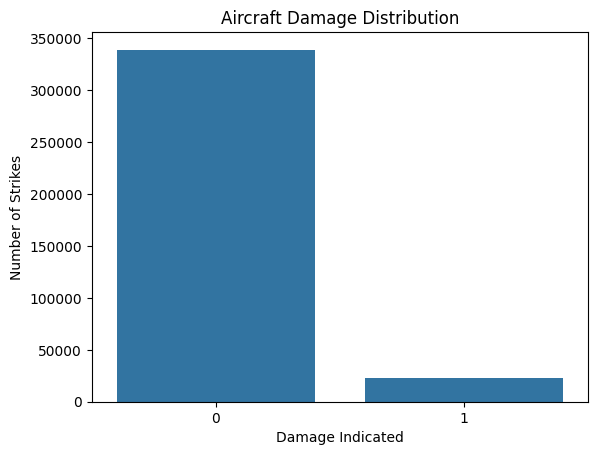

In [20]:
sns.countplot(data=df, x="INDICATED_DAMAGE")
plt.title("Aircraft Damage Distribution")
plt.xlabel("Damage Indicated")
plt.ylabel("Number of Strikes")
plt.show()

### Aircraft Damage

`INDICATED_DAMAGE` is the target variable for this project, where 1 indicates reported aircraft damage and 0 indicates no reported damage.

Only 22,367 of 361,180 reported strikes (about 6.2%) indicate aircraft damage, so the target is highly imbalanced. Because most strikes do not result in damage, accuracy alone may be misleading when evaluating classification models.

Analyze which columns are relevant to the problem and drop extra ones.

In [23]:
with pd.option_context("display.max_rows", None):
    display(column_summary)

,dtype,non_null,missing,missing_pct,unique
INDEX_NR,int64,361408,0,0.0,361400
INCIDENT_DATE,object,361408,0,0.0,13377
INCIDENT_MONTH,int64,361408,0,0.0,12
INCIDENT_YEAR,int64,361408,0,0.0,37
TIME,object,240117,121291,33.6,1441
TIME_OF_DAY,object,203405,158003,43.7,4
AIRPORT_ID,object,361408,0,0.0,2811
AIRPORT,object,361408,0,0.0,2811
LATITUDE,object,312254,49154,13.6,2802
LONGITUDE,object,312248,49160,13.6,2803


### Feature Selection

The FAA dataset contains 102 columns. I selected 16 features describing wildlife, aircraft, flight conditions, location, and environmental characteristics to predict whether a wildlife strike resulted in aircraft damage.

The target variable is `INDICATED_DAMAGE`, where 0 represents no reported damage and 1 represents reported damage.

Identifiers, redundant fields, administrative information, and damage-related outcomes were excluded to reduce unnecessary complexity and avoid data leakage. The selected features will be evaluated and refined during modeling.

In [25]:
target = "INDICATED_DAMAGE"

In [27]:
selected_features = ["INCIDENT_MONTH", "TIME_OF_DAY", "FAAREGION", "SKY", "PHASE_OF_FLIGHT", "HEIGHT", "SPEED", "DISTANCE", "AC_CLASS", "AC_MASS", "TYPE_ENG", "NUM_ENGS", "SIZE", "NUM_SEEN", "NUM_STRUCK", "WARNED"]

In [28]:
X = df[selected_features].copy()
y = df["INDICATED_DAMAGE"].copy()

In [29]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (361408, 16)
Target: (361408,)


In [30]:
print(y.value_counts())
print("\nDamage percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

INDICATED_DAMAGE
0    339036
1     22372
Name: count, dtype: int64

Damage percentages:
INDICATED_DAMAGE
0    93.81
1     6.19
Name: proportion, dtype: float64


The target variable is imbalanced, with approximately 6% of reported wildlife strikes indicating aircraft damage. This imbalance will be considered during model training and evaluation, since accuracy alone may not adequately reflect the model's ability to identify damaging strikes.

### Preprocessing Selected Features

After selecting the relevant features, I examine their missing values and data types before training the models. Missing numerical values will be imputed, while categorical features will be encoded into numerical representations that machine learning models can process.

In [31]:
print("Missing values:")
print(X.isna().sum())

print("\nData types:")
print(X.dtypes)

Missing values:
INCIDENT_MONTH          0
TIME_OF_DAY        158003
FAAREGION           49154
SKY                194137
PHASE_OF_FLIGHT    143284
HEIGHT             183046
SPEED              250684
DISTANCE           121603
AC_CLASS           102468
AC_MASS            102616
TYPE_ENG           102938
NUM_ENGS           102916
SIZE                43248
NUM_SEEN           246579
NUM_STRUCK            764
WARNED                  0
dtype: int64

Data types:
INCIDENT_MONTH       int64
TIME_OF_DAY         object
FAAREGION           object
SKY                 object
PHASE_OF_FLIGHT     object
HEIGHT             float64
SPEED              float64
DISTANCE           float64
AC_CLASS            object
AC_MASS            float64
TYPE_ENG            object
NUM_ENGS           float64
SIZE                object
NUM_SEEN            object
NUM_STRUCK          object
WARNED              object
dtype: object


In [32]:
# Replace blank strings with missing values
X = X.replace(r"^\s*$", np.nan, regex=True)

In [33]:
# Categorical features
categorical_features = [
    "INCIDENT_MONTH", "TIME_OF_DAY", "FAAREGION",
    "SKY", "PHASE_OF_FLIGHT", "AC_CLASS",
    "AC_MASS", "TYPE_ENG", "SIZE",
    "NUM_SEEN", "NUM_STRUCK", "WARNED"
]

In [34]:
# Treat numeric category codes as categories
X["INCIDENT_MONTH"] = X["INCIDENT_MONTH"].astype(str)
X["AC_MASS"] = X["AC_MASS"].astype("Int64").astype("string")

1. Check whether missingness relates to damage

In [35]:
missing_by_damage = X.isna().groupby(y).mean().mul(100).round(1).T
missing_by_damage.columns = ["No Damage (%)", "Damage (%)"]
missing_by_damage

,No Damage (%),Damage (%)
INCIDENT_MONTH,0.0,0.0
TIME_OF_DAY,45.4,18.7
FAAREGION,13.1,20.6
SKY,55.2,30.6
PHASE_OF_FLIGHT,41.5,12.0
HEIGHT,52.4,24.8
SPEED,71.0,44.4
DISTANCE,32.4,52.6
AC_CLASS,30.1,1.3
AC_MASS,30.2,0.9


2. Check whether aircraft information is missing together

In [36]:
aircraft_cols = ["AC_CLASS", "AC_MASS", "TYPE_ENG", "NUM_ENGS"]
X[aircraft_cols].isna().sum(axis=1).value_counts().sort_index()

,count
0,258330
1,100
2,186
3,702
4,102090


3. Inspect numeric values before imputing

In [37]:
X[["HEIGHT", "SPEED", "DISTANCE", "NUM_ENGS"]].describe()

,HEIGHT,SPEED,DISTANCE,NUM_ENGS
count,178362.000000,110724.000000,239805.000000,258492.000000
mean,879.145104,143.102634,0.880952,2.000851
std,1854.786863,46.581594,3.693171,0.403118
min,0.000000,0.000000,0.000000,1.000000
25%,0.000000,120.000000,0.000000,2.000000
50%,50.000000,140.000000,0.000000,2.000000
75%,1000.000000,160.000000,0.000000,2.000000
max,32000.000000,1000.000000,99.000000,4.000000


### Missing Data Analysis

Missing values are not distributed equally between damaging and non-damaging wildlife strikes. Aircraft and flight characteristics are generally more complete in damaging-strike reports, suggesting that reporting patterns may influence the available information.

Additionally, aircraft characteristics are frequently missing together, with 102,090 records missing all four selected aircraft attributes.

To preserve the dataset without inventing aircraft or environmental information, missing categorical values will be represented as unknown. Numerical variables will be handled through imputation and missingness indicators fitted using the training data. This approach retains incomplete records while acknowledging that missingness itself may influence model predictions.

In [38]:
X.loc[X["SPEED"] > 400, ["SPEED", "HEIGHT", "PHASE_OF_FLIGHT"]].sort_values("SPEED", ascending=False).head(20)

,SPEED,HEIGHT,PHASE_OF_FLIGHT
357192,1000.0,500.0,En Route
262590,541.0,32000.0,Descent
360129,500.0,6000.0,Approach


In [39]:
df.loc[df["SPEED"] > 400, ["INCIDENT_DATE", "AIRCRAFT", "SPEED", "HEIGHT", "PHASE_OF_FLIGHT", "REMARKS"]]

,INCIDENT_DATE,AIRCRAFT,SPEED,HEIGHT,PHASE_OF_FLIGHT,REMARKS
262590,2023-09-14,B-737-900,541.0,32000.0,Descent,"Snarge on nose and windshield. 737-924ER, Engi..."
357192,2026-08-03,AEROS 350,1000.0,500.0,En Route,DEPARTMENT OF HOMELAND SECURITY Unknown bird ...
360129,2026-08-31,B-737-7,500.0,6000.0,Approach,"SWA2127 reported strike after landing, no bird..."


### Outlier Inspection

A boxplot was used to examine the distribution of aircraft speed and identify unusually high values. Three observations exceeded 400, with a maximum recorded speed of 1,000.

Since these values could not be confirmed as errors, all observations were retained for modeling.

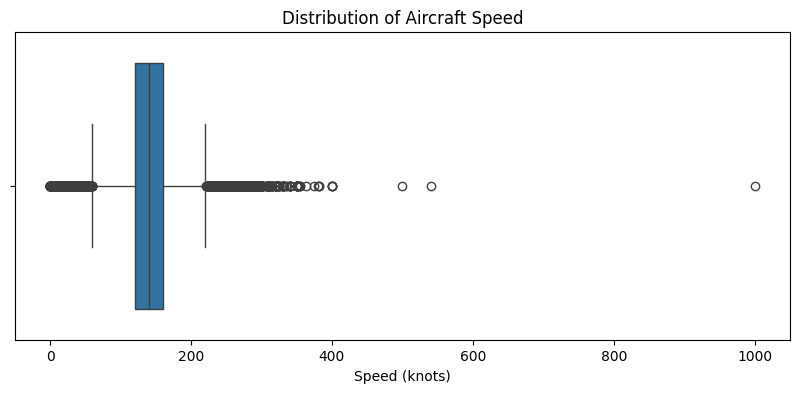

In [41]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=X["SPEED"])
plt.title("Distribution of Aircraft Speed")
plt.xlabel("Speed (knots)")
plt.show()

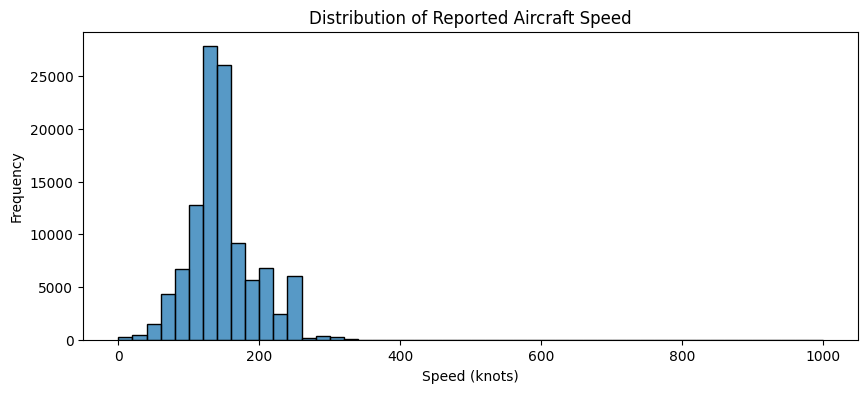

In [42]:
plt.figure(figsize=(10, 4))
sns.histplot(X["SPEED"].dropna(), bins=50)
plt.title("Distribution of Reported Aircraft Speed")
plt.xlabel("Speed (knots)")
plt.ylabel("Frequency")
plt.show()

The distribution of reported aircraft speeds is right-skewed, with most observations concentrated between approximately 100 and 200 knots. The boxplot identifies several high-speed outliers, including three observations above 400 knots.

Because these values could not be confirmed as data-entry errors, they were retained. No observations were removed during outlier inspection.

In [43]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 361408 entries, 0 to 361407
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   INCIDENT_MONTH   361408 non-null  object 
 1   TIME_OF_DAY      203405 non-null  object 
 2   FAAREGION        312254 non-null  object 
 3   SKY              167271 non-null  object 
 4   PHASE_OF_FLIGHT  218124 non-null  object 
 5   HEIGHT           178362 non-null  float64
 6   SPEED            110724 non-null  float64
 7   DISTANCE         239805 non-null  float64
 8   AC_CLASS         258940 non-null  object 
 9   AC_MASS          258792 non-null  string 
 10  TYPE_ENG         258470 non-null  object 
 11  NUM_ENGS         258492 non-null  float64
 12  SIZE             318160 non-null  object 
 13  NUM_SEEN         114829 non-null  object 
 14  NUM_STRUCK       360644 non-null  object 
 15  WARNED           361408 non-null  object 
dtypes: float64(4), object(11), string(1)
m

In [44]:
X.head()

,INCIDENT_MONTH,TIME_OF_DAY,FAAREGION,SKY,PHASE_OF_FLIGHT,HEIGHT,SPEED,DISTANCE,AC_CLASS,AC_MASS,TYPE_ENG,NUM_ENGS,SIZE,NUM_SEEN,NUM_STRUCK,WARNED
0,6,NaN,AWP,NaN,Take-off Run,0.0,NaN,0.0,A,4,D,2.0,Medium,NaN,1,Unknown
1,6,NaN,ANM,NaN,Take-off Run,0.0,NaN,0.0,A,4,D,2.0,Medium,NaN,1,Unknown
2,7,NaN,ACE,NaN,Take-off Run,0.0,NaN,0.0,A,4,D,2.0,Medium,NaN,1,Unknown
3,7,NaN,AEA,NaN,Approach,1000.0,NaN,NaN,A,4,D,2.0,Medium,NaN,1,Unknown
4,7,NaN,AEA,NaN,Climb,5000.0,NaN,NaN,A,4,D,2.0,Medium,NaN,1,Unknown


In [45]:
for col in X.columns:
    print(f"\n--- {col} ---")
    print(X[col].value_counts(dropna=False))


--- INCIDENT_MONTH ---
INCIDENT_MONTH
8     51636
9     47743
7     47143
10    43802
5     36742
6     30952
4     26387
11    23840
3     17257
12    13394
1     11455
2     11057
Name: count, dtype: int64

--- TIME_OF_DAY ---
TIME_OF_DAY
NaN      158003
Day      124279
Night     63326
Dusk       8902
Dawn       6898
Name: count, dtype: int64

--- FAAREGION ---
FAAREGION
ASO    68600
NaN    49154
AGL    48704
AEA    47384
ASW    43177
AWP    37942
ANM    32955
ACE    14433
ANE    11379
FGN     5950
AAL     1730
Name: count, dtype: int64

--- SKY ---
SKY
NaN           194137
No Cloud       81725
Some Cloud     57752
Overcast       27794
Name: count, dtype: int64

--- PHASE_OF_FLIGHT ---
PHASE_OF_FLIGHT
NaN             143284
Approach         92253
Landing Roll     40025
Take-off Run     36162
Climb            31785
En Route          6504
Departure         4395
Descent           3141
Local             1570
Arrival           1287
Taxi               877
Parked             118
Unknown   

## Visualize damage rates across features

In [46]:
damage_by_size = df.groupby("SIZE")["INDICATED_DAMAGE"].mean().mul(100).sort_values(ascending=False)

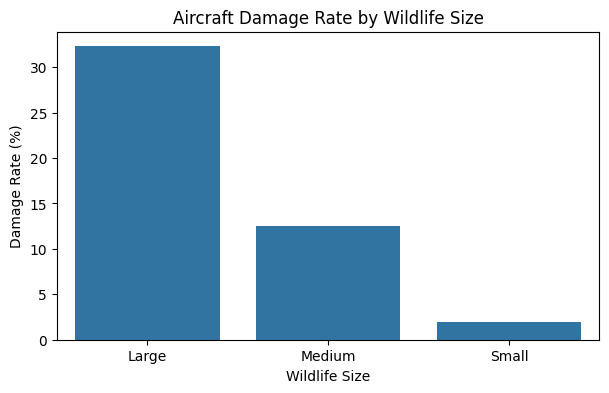

In [47]:
plt.figure(figsize=(7, 4))
sns.barplot(x=damage_by_size.index, y=damage_by_size.values)
plt.title("Aircraft Damage Rate by Wildlife Size")
plt.xlabel("Wildlife Size")
plt.ylabel("Damage Rate (%)")
plt.show()

## Damage rate by flight phase

In [48]:
damage_by_phase = df.groupby("PHASE_OF_FLIGHT")["INDICATED_DAMAGE"].mean().mul(100).sort_values(ascending=False)

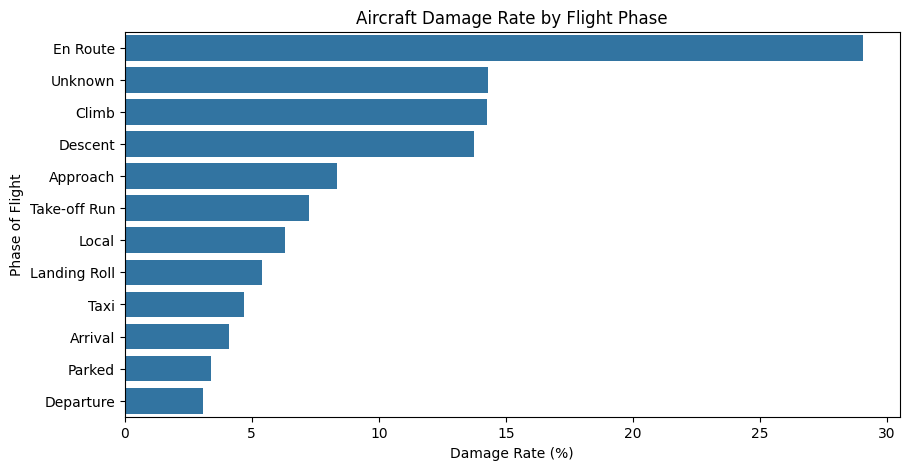

In [49]:
plt.figure(figsize=(10, 5))
sns.barplot(x=damage_by_phase.values, y=damage_by_phase.index)
plt.title("Aircraft Damage Rate by Flight Phase")
plt.xlabel("Damage Rate (%)")
plt.ylabel("Phase of Flight")
plt.show()

## Visualize missingness across all selected features

In [50]:
missing_pct = X.isna().mean().mul(100).sort_values()

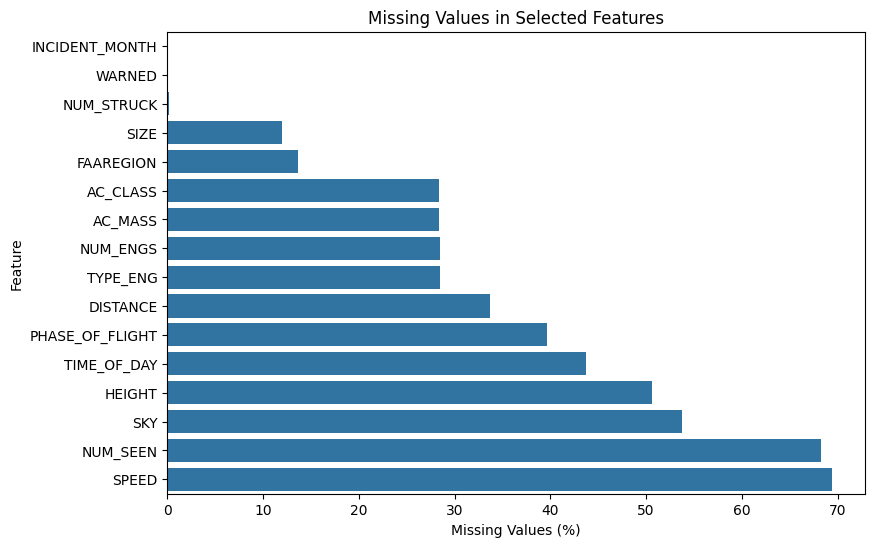

In [51]:
plt.figure(figsize=(9, 6))
sns.barplot(x=missing_pct.values, y=missing_pct.index)
plt.title("Missing Values in Selected Features")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.show()

### Exploratory Analysis Findings

Wildlife size and flight phase show noticeable differences in reported aircraft damage rates. Large wildlife strikes have the highest damage rate among the size categories, while en-route strikes have the highest damage rate among recorded flight phases.

Several selected features also contain substantial missing information. To avoid discarding observations, missing values will be addressed during preprocessing rather than removing incomplete records.

## Prepare the data

### Data Preparation Decisions

After examining the selected features, their missing values, and their relationships with aircraft damage, the following decisions were made:

- **Feature selection:** `AC_CLASS` was excluded because most recorded values belong to one category, while `NUM_SEEN` was excluded because approximately 68% of its values are missing. The remaining 14 features were retained for initial modeling.
- **Categorical variables:** Missing values in features such as `TIME_OF_DAY`, `FAAREGION`, `SKY`, and `PHASE_OF_FLIGHT` will be represented as `"Unknown"` rather than assuming a particular condition.
- **Aircraft characteristics:** `AC_MASS` and `NUM_ENGS` will be treated as categorical variables. Missing values will not be replaced with assumed aircraft characteristics.
- **Numerical variables:** `HEIGHT`, `SPEED`, and `DISTANCE` will remain numerical. Missing values will be handled through median imputation and missingness indicators.
- **Outliers:** Unusually high aircraft speeds were inspected but retained because they could not be confirmed as errors.
- **Class imbalance:** Only 6.19% of records report aircraft damage. Stratified splitting will preserve this distribution, and class weighting will be considered during model training.

To prevent data leakage, numerical imputation and categorical encoding will be fitted using training data only. No observations will be removed solely because they contain missing values.

There for 14 features are:

In [52]:
selected_features = [
    "INCIDENT_MONTH", "TIME_OF_DAY", "FAAREGION", "SKY",
    "PHASE_OF_FLIGHT", "HEIGHT", "SPEED", "DISTANCE",
    "AC_MASS", "TYPE_ENG", "NUM_ENGS", "SIZE",
    "NUM_STRUCK", "WARNED"
]

In [53]:
X = df[selected_features].copy()
y = df["INDICATED_DAMAGE"].copy()

In [54]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (361408, 14)
Target: (361408,)


**Prepare categorical values**

In [55]:
numeric_cols = ["HEIGHT", "SPEED", "DISTANCE"]
categorical_cols = X.columns.difference(numeric_cols).tolist()

standardize categorical values:

In [56]:
X[categorical_cols] = X[categorical_cols].astype("string")
X[categorical_cols] = X[categorical_cols].apply(lambda col: col.str.strip()).replace("", pd.NA)
X[categorical_cols] = X[categorical_cols].fillna("Unknown").astype(str)

In [57]:
X[categorical_cols].isna().sum()

,0
AC_MASS,0
FAAREGION,0
INCIDENT_MONTH,0
NUM_ENGS,0
NUM_STRUCK,0
PHASE_OF_FLIGHT,0
SIZE,0
SKY,0
TIME_OF_DAY,0
TYPE_ENG,0
